# Oral Cancer Detection using CNNs (Transfer Learning)

Four-class classification of oral cavity photographs — **Healthy / Benign / OPMD / OCA** — comparing
MobileNetV2 and DenseNet121, plus a simple lifestyle risk score.

**Setup:** `pip install -r requirements.txt`, then copy the dataset files (`Images.zip`,
`Imagewise_data.csv`, `Patientwise_data.csv`) into the `data` folder next to this notebook.

> Research/educational project only. This is not a medical device and must not be used for diagnosis.

In [1]:
import json
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


## Configuration

In [2]:
# Dataset location: the "data" folder next to this notebook, or set the ORAL_DATA_DIR environment variable.
# Put the files from Zenodo there as downloaded: Images.zip (or an extracted Images folder),
# Imagewise_data.csv, Patientwise_data.csv and Annotation.json (optional, used to crop to the mouth).
DATA_DIR = Path(os.environ.get("ORAL_DATA_DIR", "data"))
IMAGE_FOLDER = DATA_DIR / "Images"


def find_file(name):
    """Find a file in DATA_DIR ignoring upper/lower case (Imagewise_Data.csv vs Imagewise_data.csv)."""
    if DATA_DIR.is_dir():
        for p in DATA_DIR.iterdir():
            if p.name.lower() == name.lower():
                return p
    return DATA_DIR / name


images_zip = find_file("Images.zip")
if not IMAGE_FOLDER.exists() and images_zip.exists():
    print("Extracting", images_zip, "...")
    with zipfile.ZipFile(images_zip) as zf:
        zf.extractall(IMAGE_FOLDER)

IMAGEWISE_CSV = find_file("Imagewise_Data.csv")
PATIENTWISE_CSV = find_file("Patientwise_Data.csv")
ANNOTATION_JSON = find_file("Annotation.json")

missing = [str(p) for p in (IMAGE_FOLDER, IMAGEWISE_CSV, PATIENTWISE_CSV) if not p.exists()]
if missing:
    raise FileNotFoundError(
        f"Dataset not found in {DATA_DIR.resolve()}.\n"
        "Copy Images.zip, Imagewise_data.csv and Patientwise_data.csv into that folder "
        "(or set ORAL_DATA_DIR to where they are).\nMissing:\n  " + "\n  ".join(missing)
    )

IMG_SIZE = 224
DECODE_RATIO = 4      # the photos are 8-16 megapixels; decode them at 1/4 size (much faster)
CROP_MARGIN = 0.05    # extra border kept around the oral-cavity box
BATCH_SIZE = 32
CLASS_NAMES = ["Healthy", "Benign", "OPMD", "OCA"]
NUM_CLASSES = len(CLASS_NAMES)
label_map = {name: i for i, name in enumerate(CLASS_NAMES)}

# ORAL_SMOKE=1 runs one epoch per stage, just to check the pipeline end to end.
SMOKE_TEST = os.environ.get("ORAL_SMOKE") == "1"
HEAD_EPOCHS = 1 if SMOKE_TEST else 10       # stage 1: train the new classification head
FINE_TUNE_EPOCHS = 1 if SMOKE_TEST else 30  # stage 2: fine-tune the backbone
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-4
FINE_TUNE_LAYERS = None   # how many of the backbone's last layers to fine-tune (None = all)

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

## Load the metadata

In [3]:
img_data = pd.read_csv(IMAGEWISE_CSV)
patient_data = pd.read_csv(PATIENTWISE_CSV)
img_data.columns = img_data.columns.str.strip()
patient_data.columns = patient_data.columns.str.strip()

print(img_data.head())
print(patient_data.head())

  Image Name Category Clinical Diagnosis  Lesion Annotation Count
0    R-01-01     OPMD        Leukoplakia                        1
1    R-01-02     OPMD        Leukoplakia                        1
2    R-01-03   Benign      Coated Tongue                        1
3    R-02-01   Benign                VBD                        1
4    R-02-02   Benign                VBD                        1
  Patient ID  Age Gender Smoking Chewing_Betel_Quid Alcohol  Image Count
0       R-01   63      M      No                 No      No            3
1       R-02   17      F      No                 No      No            8
2       R-03   70      M      No                 No      No            5
3       R-04   45      M      No                 No      No            5
4       R-05   46      M      No                Yes      No            2


In [4]:
# Match each row to its image file (any .jpg/.jpeg, case-insensitive, also inside subfolders).
image_index = {
    p.stem.lower(): str(p)
    for p in IMAGE_FOLDER.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg"}
}
img_data["Image Name"] = img_data["Image Name"].astype(str).str.strip()
img_data["path"] = img_data["Image Name"].str.lower().map(image_index)
img_data["label"] = img_data["Category"].astype(str).str.strip().map(label_map)

n_before = len(img_data)
no_file = img_data["path"].isna()
no_label = img_data["label"].isna()
if no_file.any():
    print(f"WARNING: {no_file.sum()} rows have no image file, e.g. {img_data.loc[no_file, 'Image Name'].head(5).tolist()}")
if no_label.any():
    print(f"WARNING: {no_label.sum()} rows have an unknown category: {img_data.loc[no_label, 'Category'].unique().tolist()}")
img_data = img_data[~(no_file | no_label)].reset_index(drop=True)
img_data["label"] = img_data["label"].astype("int32")

# The patient ID is the first two parts of the image name: "R-01-03" -> "R-01", "C-10-12-5" -> "C-10".
img_data["patient_id"] = img_data["Image Name"].str.split("-").str[:2].str.join("-")
unknown_patients = set(img_data["patient_id"]) - set(patient_data["Patient ID"].astype(str).str.strip())
if unknown_patients:
    print(f"WARNING: {len(unknown_patients)} patient IDs are not in the patient table, e.g. {sorted(unknown_patients)[:5]}")

# Phone photos often store their rotation in an EXIF tag instead of rotating the pixels. TensorFlow ignores
# that tag, so read it here and rotate when loading (the annotation boxes refer to the upright image).
def exif_rot90(path):
    """Number of counter-clockwise 90-degree turns needed to make the image upright."""
    with Image.open(path) as im:
        return {3: 2, 6: 3, 8: 1}.get(im.getexif().get(274, 1), 0)


img_data["rot90"] = img_data["path"].map(exif_rot90).astype("int32")

# Oral-cavity bounding boxes [x, y, width, height] from Annotation.json (COCO format).
# [0, 0, 0, 0] means "no box - use the whole photo".
NO_BOX = [0.0, 0.0, 0.0, 0.0]
cavity_boxes = {}
if ANNOTATION_JSON.exists():
    with open(ANNOTATION_JSON, encoding="utf-8") as f:
        coco = json.load(f)
    cavity_ids = {c["id"] for c in coco["categories"] if c["name"].strip().lower() == "oral cavity"}
    stems = {im["id"]: Path(im["file_name"]).stem.lower() for im in coco["images"]}
    for ann in coco["annotations"]:
        if ann["category_id"] not in cavity_ids:
            continue
        x, y, w, h = ann["bbox"]
        key = stems[ann["image_id"]]
        if key in cavity_boxes:          # more than one box: use the area covering both
            px, py, pw, ph = cavity_boxes[key]
            x0, y0 = min(x, px), min(y, py)
            w, h = max(x + w, px + pw) - x0, max(y + h, py + ph) - y0
            x, y = x0, y0
        cavity_boxes[key] = [float(x), float(y), float(w), float(h)]
else:
    print("Annotation.json not found - training on the whole photos instead of oral-cavity crops")
img_data["box"] = [cavity_boxes.get(name.lower(), NO_BOX) for name in img_data["Image Name"]]
print(f"Oral-cavity boxes found for {sum(b != NO_BOX for b in img_data['box'])} of {len(img_data)} images;"
      f" {(img_data['rot90'] > 0).sum()} images need rotating")

print(f"Using {len(img_data)} of {n_before} images from {img_data['patient_id'].nunique()} patients")
print(img_data["Category"].value_counts())

Oral-cavity boxes found for 2999 of 3000 images; 145 images need rotating
Using 3000 of 3000 images from 714 patients
Category
OPMD       1394
Benign      748
Healthy     729
OCA         129
Name: count, dtype: int64


## Train / validation / test split

The split is made **by patient**, so photos of the same mouth never appear in both training and
evaluation data, and it is made **before** any class balancing. (Oversampling the OCA class before
splitting, as in the first version of this notebook, puts copies of the same image in both the
training and the test set and inflates the OCA scores.)

A separate validation set is used for early stopping and model selection; the test set is only
used for the final report.

In [5]:
def group_split(df, n_splits, seed):
    """Hold out roughly 1/n_splits of the patients, stratified by label."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest_idx, held_idx = next(sgkf.split(df, df["label"], groups=df["patient_id"]))
    return df.iloc[rest_idx].reset_index(drop=True), df.iloc[held_idx].reset_index(drop=True)


trainval_df, test_df = group_split(img_data, 5, SEED)   # ~20% test
train_df, val_df = group_split(trainval_df, 5, SEED)    # ~16% validation, ~64% train

assert not set(train_df["patient_id"]) & set(test_df["patient_id"])
assert not set(train_df["patient_id"]) & set(val_df["patient_id"])
assert not set(val_df["patient_id"]) & set(test_df["patient_id"])

split_counts = pd.DataFrame({
    name: df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]
})
split_counts.index = CLASS_NAMES
print(split_counts)

         train  val  test
Healthy    467  116   146
Benign     479  120   149
OPMD       892  223   279
OCA         82   21    26


In [6]:
# Handle class imbalance with class weights computed on the training set only.
present = np.unique(train_df["label"])
weights = compute_class_weight("balanced", classes=present, y=train_df["label"].to_numpy())
class_weight = {int(c): float(w) for c, w in zip(present, weights)}
print("Class weights:", {CLASS_NAMES[c]: round(w, 2) for c, w in class_weight.items()})

Class weights: {'Healthy': 1.03, 'Benign': 1.0, 'OPMD': 0.54, 'OCA': 5.85}


## Input pipeline

One `load_image` function is used for training, evaluation and single-image prediction, so the
model always sees images prepared the same way: upright and cropped to the oral cavity, so the
mouth fills the frame instead of lips, skin and background. Images stay in the raw 0–255 range here; the
backbone-specific normalisation lives inside each model.

In [7]:
def load_image(path, box=NO_BOX, rot90=0):
    """Read a photo, make it upright, crop it to the oral-cavity box (if any) and resize it.

    Returns a float32 RGB tensor (IMG_SIZE, IMG_SIZE, 3) in [0, 255].
    box is [x, y, width, height] in pixels of the upright full-size photo; all zeros = whole photo.
    """
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3, ratio=DECODE_RATIO, try_recover_truncated=True)
    img = tf.image.rot90(img, k=rot90)

    height = tf.cast(tf.shape(img)[0], tf.float32)
    width = tf.cast(tf.shape(img)[1], tf.float32)
    x, y, w, h = tf.unstack(tf.cast(box, tf.float32) / DECODE_RATIO)
    has_box = tf.logical_and(w > 1, h > 1)
    x0 = tf.where(has_box, tf.clip_by_value(x - CROP_MARGIN * w, 0.0, width - 2), 0.0)
    y0 = tf.where(has_box, tf.clip_by_value(y - CROP_MARGIN * h, 0.0, height - 2), 0.0)
    x1 = tf.where(has_box, tf.clip_by_value(x + (1 + CROP_MARGIN) * w, x0 + 2, width), width)
    y1 = tf.where(has_box, tf.clip_by_value(y + (1 + CROP_MARGIN) * h, y0 + 2, height), height)
    img = tf.image.crop_to_bounding_box(
        img, tf.cast(y0, tf.int32), tf.cast(x0, tf.int32), tf.cast(y1 - y0, tf.int32), tf.cast(x1 - x0, tf.int32)
    )

    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    return tf.clip_by_value(img, 0.0, 255.0)


augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),            # about +/- 20 degrees
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
], name="augmentation")


def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["path"].astype(str).tolist(),
        np.array(df["box"].tolist(), dtype="float32"),
        df["rot90"].to_numpy(dtype="int32"),
        df["label"].to_numpy(dtype="int32"),
    ))
    # Cache the resized images (as uint8 to save memory) so files are decoded only once.
    ds = ds.map(lambda p, b, r, y: (tf.cast(load_image(p, b, r), tf.uint8), y),
                num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y))
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

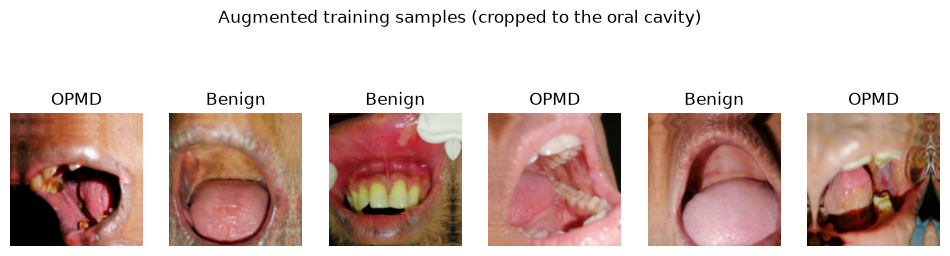

In [8]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(12, 3.5))
for i in range(min(6, len(images))):
    plt.subplot(1, 6, i + 1)
    plt.imshow(np.clip(images[i].numpy(), 0, 255).astype("uint8"))
    plt.title(CLASS_NAMES[int(labels[i])])
    plt.axis("off")
plt.suptitle("Augmented training samples (cropped to the oral cavity)")
plt.show()

## Models

Both models use an ImageNet-pretrained backbone with a small classification head. Each backbone
gets the input normalisation it was pretrained with (MobileNetV2: scale to [-1, 1]; DenseNet121:
ImageNet mean/std) — feeding both plain `1/255`-scaled images, as before, hurts transfer learning.

Training is two-stage: first only the head (backbone frozen), then the whole backbone is fine-tuned
with a lower learning rate. BatchNorm layers stay frozen during fine-tuning. On this dataset,
fine-tuning the whole backbone worked clearly better than fine-tuning only its last 40 layers
(validation macro-F1 0.51 vs 0.43 for MobileNetV2).

In [9]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406]) * 255.0
IMAGENET_STD = np.array([0.229, 0.224, 0.225]) * 255.0

BACKBONES = {
    "MobileNetV2": (
        keras.applications.MobileNetV2,
        lambda: layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocess"),
    ),
    "DenseNet121": (
        keras.applications.DenseNet121,
        lambda: layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_STD ** 2, name="preprocess"),
    ),
}


def build_model(backbone_name):
    constructor, make_preprocess = BACKBONES[backbone_name]
    base = constructor(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")   # raw RGB, 0-255
    x = make_preprocess()(inputs)
    x = base(x, training=False)                                    # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=backbone_name), base


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.3),
    ]


def train_two_stage(backbone_name):
    model, base = build_model(backbone_name)

    # Stage 1: train the head only.
    compile_model(model, HEAD_LR)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                   class_weight=class_weight, callbacks=make_callbacks())
    stage1_weights = MODEL_DIR / f"{backbone_name}_stage1.weights.h5"
    model.save_weights(stage1_weights)
    stage1_val_loss = model.evaluate(val_ds, verbose=0)[0]

    # Stage 2: fine-tune the backbone (BatchNorm stays frozen).
    base.trainable = True
    if FINE_TUNE_LAYERS is not None:
        for layer in base.layers[:-FINE_TUNE_LAYERS]:
            layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, FINE_TUNE_LR)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
                   class_weight=class_weight, callbacks=make_callbacks())

    # Keep the stage-1 weights if fine-tuning did not help.
    if model.evaluate(val_ds, verbose=0)[0] > stage1_val_loss:
        print(f"{backbone_name}: fine-tuning did not improve validation loss; keeping stage-1 weights")
        model.load_weights(stage1_weights)

    history = {k: h1.history[k] + h2.history[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
    return model, history, len(h1.history["loss"])

## Evaluation helpers

In [10]:
def plot_history(history, fine_tune_start, title):
    plt.figure(figsize=(14, 5))
    for i, metric in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history[metric], label="Train")
        plt.plot(history["val_" + metric], label="Validation")
        plt.axvline(fine_tune_start - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
        plt.title(f"{title} - {metric.capitalize()}")
        plt.xlabel("Epoch")
        plt.legend()
    plt.tight_layout()
    plt.show()


def predict_labels(model, ds):
    return np.argmax(model.predict(ds, verbose=0), axis=1)


def evaluate_on_test(model, title):
    y_true = test_df["label"].to_numpy()
    y_pred = predict_labels(model, test_ds)
    all_labels = list(range(NUM_CLASSES))

    cm = confusion_matrix(y_true, y_pred, labels=all_labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix - {title}")
    plt.show()

    print(f"Classification Report - {title}")
    print(classification_report(y_true, y_pred, labels=all_labels, target_names=CLASS_NAMES, zero_division=0))
    report = classification_report(y_true, y_pred, labels=all_labels, target_names=CLASS_NAMES,
                                   zero_division=0, output_dict=True)
    return {
        "val_macro_f1": f1_score(val_df["label"].to_numpy(), predict_labels(model, val_ds),
                                 labels=all_labels, average="macro", zero_division=0),
        "test_accuracy": report["accuracy"],
        "test_macro_f1": report["macro avg"]["f1-score"],
        "test_OCA_recall": report["OCA"]["recall"],
    }

## MobileNetV2

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 59s 848ms/step - accuracy: 0.2896 - loss: 1.6019 - val_accuracy: 0.3229 - val_loss: 1.4139 - learning_rate: 0.0010
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 65s 576ms/step - accuracy: 0.3583 - loss: 1.3559 - val_accuracy: 0.4917 - val_loss: 1.1798 - learning_rate: 0.0010
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 46s 657ms/step - accuracy: 0.3812 - loss: 1.3312 - val_accuracy: 0.4250 - val_loss: 1.2286 - learning_rate: 0.0010
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 75s 533ms/step - accuracy: 0.4198 - loss: 1.2212 - val_accuracy: 0.4167 - val_loss: 1.2414 - learning_rate: 0.0010
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 42s 551ms/step - accuracy: 0.4401 - loss: 1.1925 - val_accuracy: 0.3958 - val_loss: 1.3969 - learning_rate: 0.0010
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 35s 540ms/step - accuracy: 0.4573 - loss: 1.1190 - val_accuracy: 0.4458 - val_loss: 1.2392 - learning_rate: 3.0000e-04
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 29s 428ms/step - accuracy: 0.4490 - loss

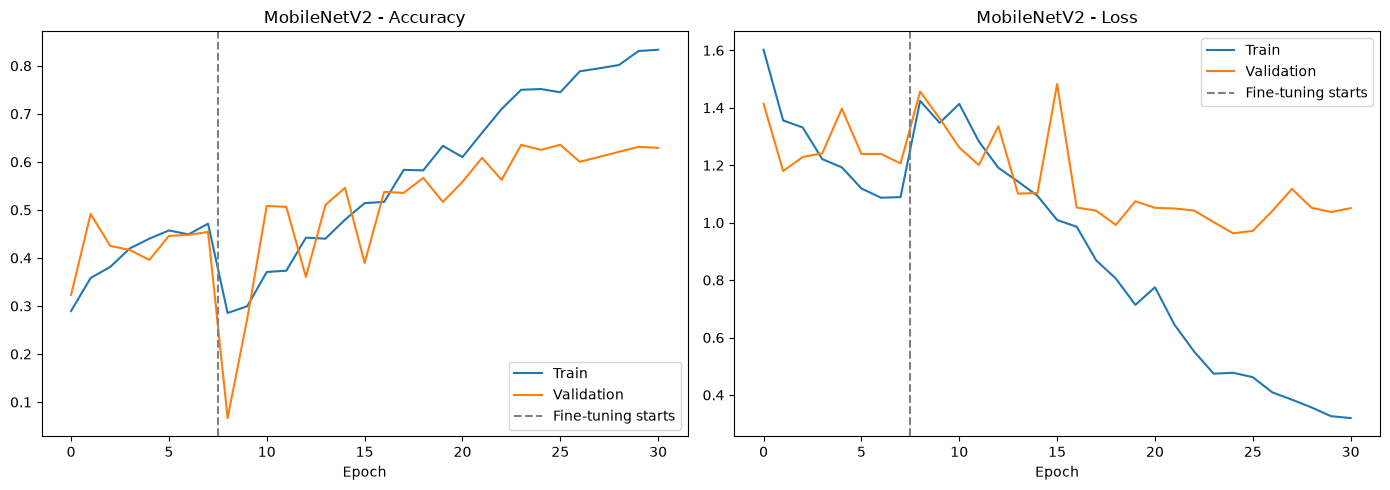

In [11]:
models, histories, results = {}, {}, {}

models["MobileNetV2"], histories["MobileNetV2"], ft_start = train_two_stage("MobileNetV2")
plot_history(histories["MobileNetV2"], ft_start, "MobileNetV2")

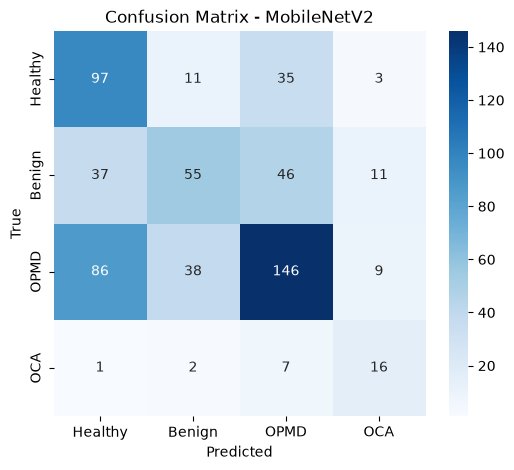

Classification Report - MobileNetV2
              precision    recall  f1-score   support

     Healthy       0.44      0.66      0.53       146
      Benign       0.52      0.37      0.43       149
        OPMD       0.62      0.52      0.57       279
         OCA       0.41      0.62      0.49        26

    accuracy                           0.52       600
   macro avg       0.50      0.54      0.51       600
weighted avg       0.54      0.52      0.52       600



In [12]:
results["MobileNetV2"] = evaluate_on_test(models["MobileNetV2"], "MobileNetV2")
models["MobileNetV2"].save(MODEL_DIR / "oral_cancer_mobilenetv2.keras")

## DenseNet121

DenseNet121 connects each layer to all previous layers, which encourages feature reuse and good
gradient flow, and it is widely used in medical image analysis. It is trained with exactly the same
data, head and schedule as MobileNetV2 so the two can be compared fairly.

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 174s 3s/step - accuracy: 0.2807 - loss: 1.6954 - val_accuracy: 0.3042 - val_loss: 1.4197 - learning_rate: 0.0010
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.3156 - loss: 1.4969 - val_accuracy: 0.3812 - val_loss: 1.3363 - learning_rate: 0.0010
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.3474 - loss: 1.4305 - val_accuracy: 0.3562 - val_loss: 1.3270 - learning_rate: 0.0010
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.3604 - loss: 1.3583 - val_accuracy: 0.4375 - val_loss: 1.2245 - learning_rate: 0.0010
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.3974 - loss: 1.2942 - val_accuracy: 0.3688 - val_loss: 1.3697 - learning_rate: 0.0010
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 190s 2s/step - accuracy: 0.4010 - loss: 1.2294 - val_accuracy: 0.4958 - val_loss: 1.1281 - learning_rate: 0.0010
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.4031 - loss: 1.2755 - val_acc

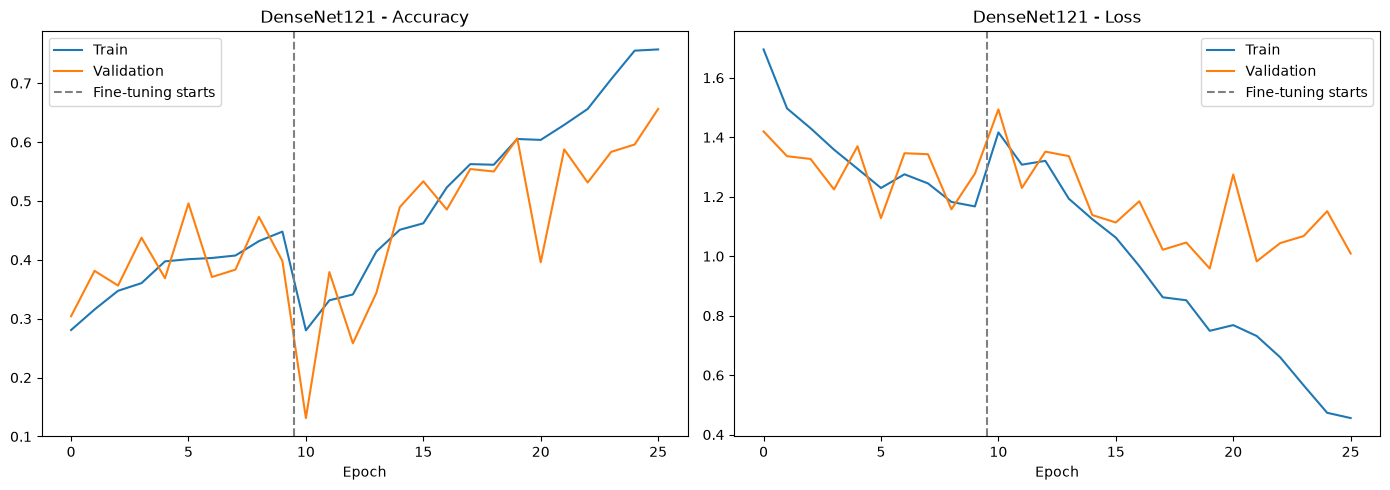

In [13]:
models["DenseNet121"], histories["DenseNet121"], ft_start = train_two_stage("DenseNet121")
plot_history(histories["DenseNet121"], ft_start, "DenseNet121")

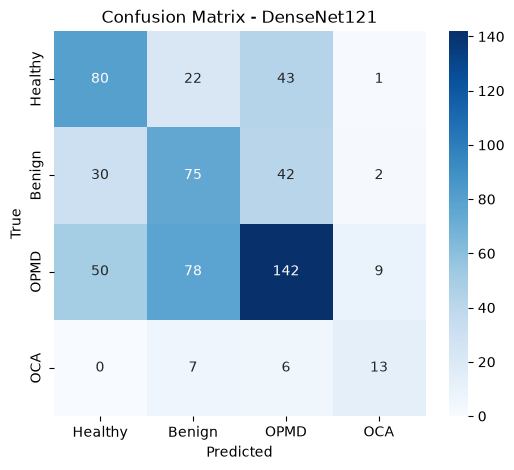

Classification Report - DenseNet121
              precision    recall  f1-score   support

     Healthy       0.50      0.55      0.52       146
      Benign       0.41      0.50      0.45       149
        OPMD       0.61      0.51      0.55       279
         OCA       0.52      0.50      0.51        26

    accuracy                           0.52       600
   macro avg       0.51      0.52      0.51       600
weighted avg       0.53      0.52      0.52       600



In [14]:
results["DenseNet121"] = evaluate_on_test(models["DenseNet121"], "DenseNet121")
models["DenseNet121"].save(MODEL_DIR / "oral_cancer_densenet121.keras")

## Comparison

The model used for prediction below is chosen by **validation** macro-F1 (not test), so the test
numbers stay an unbiased estimate. Macro-F1 and OCA recall matter more than accuracy here because
the classes are imbalanced and missing a cancer is the costliest error.

             val_macro_f1  test_accuracy  test_macro_f1  test_OCA_recall
MobileNetV2         0.558          0.523          0.505            0.615
DenseNet121         0.538          0.517          0.510            0.500


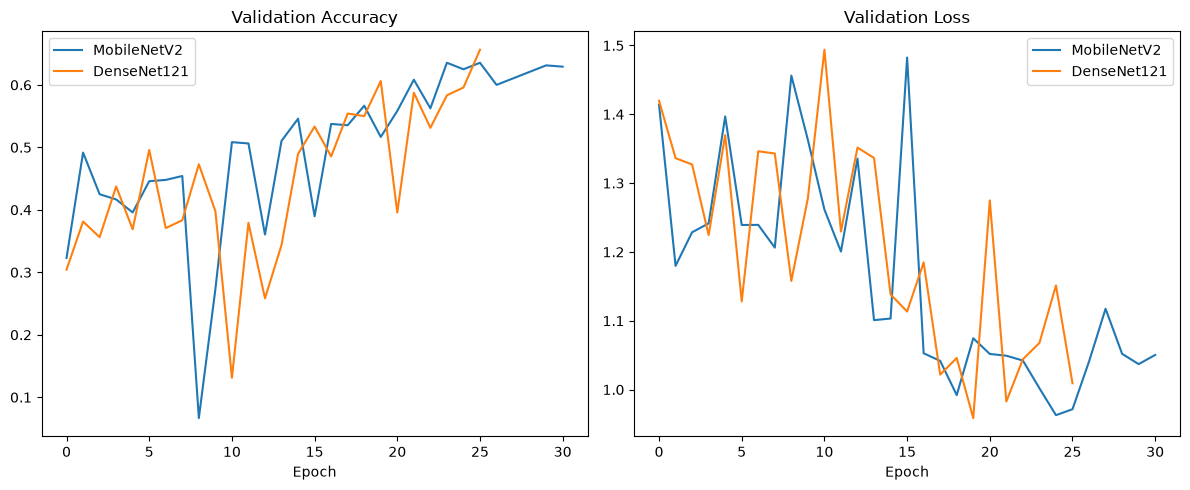

Best model (by validation macro-F1): MobileNetV2


In [15]:
results_df = pd.DataFrame(results).T.round(3)
print(results_df)

plt.figure(figsize=(12, 5))
for i, metric in enumerate(["val_accuracy", "val_loss"]):
    plt.subplot(1, 2, i + 1)
    for name, history in histories.items():
        plt.plot(history[metric], label=name)
    plt.title("Validation " + metric.split("_")[1].capitalize())
    plt.xlabel("Epoch")
    plt.legend()
plt.tight_layout()
plt.show()

best_name = results_df["val_macro_f1"].idxmax()
best_model = models[best_name]
best_model.save(MODEL_DIR / "oral_cancer_model.keras")
print("Best model (by validation macro-F1):", best_name)

## Lifestyle risk score and combined prediction

In [16]:
def _flag(value):
    """Accept 1/0, True/False or 'Yes'/'No'."""
    if isinstance(value, str):
        return 1 if value.strip().lower() in {"yes", "y", "1", "true"} else 0
    return int(bool(value))


def risk_score(tobacco, betel, alcohol):
    score = _flag(tobacco) * 0.4 + _flag(betel) * 0.4 + _flag(alcohol) * 0.2
    if score >= 0.7:
        return "High Risk"
    elif score >= 0.3:
        return "Moderate Risk"
    return "Low Risk"


RECOMMENDATIONS = {
    # class: (message if lifestyle risk is high, message otherwise)
    "OCA": ("Findings suggestive of oral cancer - urgent specialist referral recommended.",) * 2,
    "OPMD": ("Possible pre-malignant lesion and HIGH lifestyle risk - urgent clinical evaluation recommended.",
             "Possible pre-malignant lesion (OPMD) - schedule diagnostic screening."),
    "Benign": ("Lesion appears benign but lifestyle risk is high - monitor regularly and reduce habits.",
               "Lesion appears benign - routine oral care recommended."),
    "Healthy": ("No lesion detected but lifestyle risk is high - preventive counselling advised.",
                "No lesion detected - routine oral care."),
}


def predict_full(image_path, tobacco=0, betel=0, alcohol=0, box=NO_BOX, model=None):
    """Classify one photo. The model was trained on photos cropped to the mouth, so for a new photo either
    pass box=[x, y, width, height] around the oral cavity or use a photo already framed on the mouth."""
    model = model or best_model
    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    img = load_image(str(image_path), box, exif_rot90(image_path))[tf.newaxis, ...]
    pred = model.predict(img, verbose=0)[0]
    class_id = int(np.argmax(pred))
    class_name = CLASS_NAMES[class_id]
    confidence = float(pred[class_id])
    risk = risk_score(tobacco, betel, alcohol)
    final_msg = RECOMMENDATIONS[class_name][0 if risk == "High Risk" else 1]

    print("Image Prediction:", class_name)
    print("Confidence:", round(confidence, 3))
    print("Class probabilities:", {n: round(float(p), 3) for n, p in zip(CLASS_NAMES, pred)})
    print("Lifestyle Risk:", risk)
    print("Final Recommendation:", final_msg)
    print("(Screening aid only - not a diagnosis.)")
    return class_name, pred, risk, final_msg

In [17]:
# Example: a test image, with that patient's own risk factors from the patient-wise table.
sample = test_df.iloc[0]
habits = patient_data[patient_data["Patient ID"].astype(str).str.strip() == sample["patient_id"]]
if len(habits):
    h = habits.iloc[0]
    tobacco, betel, alcohol = h["Smoking"], h["Chewing_Betel_Quid"], h["Alcohol"]
else:
    tobacco, betel, alcohol = 0, 0, 0

print("Image:", sample["Image Name"], "| true class:", sample["Category"])
_ = predict_full(sample["path"], tobacco=tobacco, betel=betel, alcohol=alcohol, box=sample["box"])

Image: R-08-01 | true class: OPMD
Image Prediction: Benign
Confidence: 0.485
Class probabilities: {'Healthy': 0.017, 'Benign': 0.485, 'OPMD': 0.153, 'OCA': 0.345}
Lifestyle Risk: Low Risk
Final Recommendation: Lesion appears benign - routine oral care recommended.
(Screening aid only - not a diagnosis.)
